# Analisis Pendapatan Per Tahun (2024 dan 2025)

Notebook ini menghitung pendapatan per tahun dari data transaksi POS.

Langkahnya:
1. Baca file CSV
2. Cek dan atasi data yang kosong (missing value)
3. Rapikan tanggal, harga, dan hapus duplikat
4. Hitung pendapatan dengan memperhatikan **status** dan **diskon**
5. Tampilkan hasil dan grafik

## 1. Baca file

In [23]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Semua kolom dibaca sebagai teks dulu, supaya format harga dan tanggal tidak salah tebak
df = pd.read_csv("paket_a_transaksi_pos_2024_2025.csv")
print("Jumlah baris:", len(df))
df.head()

Jumlah baris: 5030


,id_transaksi,tanggal,kode_gerai,kode_kasir,kode_produk,jumlah,harga_satuan,diskon_persen,status
0,TRX0241065,2025-06-02,G09,K011,RMT1402,4,13000,0,SELESAI
1,TRX0240510,2024-12-28,G09,K015,SGR1205,1,21000,0,SELESAI
2,TRX0244483,2024-09-04,G11,K029,RMT1407,3,"7500,00",0,SELESAI
3,TRX0242532,2025-07-30,G05,K001,MKN1103,2,6500,0,SELESAI
4,TRX0243509,26/03/2025,G05,K016,RMT1407,1,6000,0,SELESAI


In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5030 entries, 0 to 5029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   id_transaksi   5030 non-null   object
 1   tanggal        5030 non-null   object
 2   kode_gerai     5030 non-null   object
 3   kode_kasir     4769 non-null   object
 4   kode_produk    5030 non-null   object
 5   jumlah         5030 non-null   int64 
 6   harga_satuan   5030 non-null   object
 7   diskon_persen  5030 non-null   int64 
 8   status         5030 non-null   object
dtypes: int64(2), object(7)
memory usage: 353.8+ KB


tanggal
2025-06-01    18
2025-12-13    18
2024-12-14    18
2025-03-22    17
2024-02-24    16
              ..
26-04-2024     1
03-12-2025     1
03/08/2025     1
05/05/2024     1
04-01-2025     1
Name: count, Length: 902, dtype: int64

## 2. Cek missing value

In [28]:
print(df.isna().sum())

id_transaksi       0
tanggal            0
kode_gerai         0
kode_kasir       261
kode_produk        0
jumlah             0
harga_satuan       0
diskon_persen      0
status             0
dtype: int64


Hanya kolom `kode_kasir` yang kosong (261 baris). Kolom ini tidak dipakai untuk menghitung pendapatan,
jadi nilai kosongnya kita isi dengan `TIDAK_DIKETAHUI`.

In [31]:
df["kode_kasir"] = df["kode_kasir"].fillna("TIDAK_DIKETAHUI")
print("Missing value yang tersisa:", df.isna().sum().sum())

Missing value yang tersisa: 0


## 3. Rapikan dan hapus duplikat

In [34]:
print("Baris sebelum hapus duplikat:", len(df))
df = df.drop_duplicates()
print("Baris setelah hapus duplikat:", len(df))

Baris sebelum hapus duplikat: 5030
Baris setelah hapus duplikat: 5000


## 4. Rapikan tanggal

Tanggal ada tiga format: `2025-06-02`, `26/03/2025`, dan `26-03-2025`.
`dayfirst=True` berarti tanggal dibaca sebagai hari-bulan-tahun.

In [41]:
df["tanggal"] = pd.to_datetime(df["tanggal"], format="mixed", dayfirst=True)
df["tahun"] = df["tanggal"].dt.year
print(df["tahun"].value_counts().sort_index())

tahun
2024    2492
2025    2508
Name: count, dtype: int64


## 5. Rapikan harga

Harga masih bertipe objek dikarenakan ada yang ditulis `13.000` (titik sebagai pemisah ribuan) dan `7500,00` (koma sebagai desimal).
Caranya: buang bagian setelah koma, lalu buang titiknya.

In [43]:
def bersihkan_harga(teks):
    teks = teks.split(",")[0]      # 7500,00 -> 7500
    teks = teks.replace(".", "")   # 13.000  -> 13000
    return int(teks)

df["harga_satuan"] = df["harga_satuan"].apply(bersihkan_harga)
df[["harga_satuan", "jumlah", "diskon_persen"]].describe()

,harga_satuan,jumlah,diskon_persen
count,5000.00000,5000.000000,5000.000000
mean,22168.10000,5.611600,2.567000
std,15199.09849,68.993988,5.212576
min,4000.00000,-12.000000,0.000000
25%,11000.00000,1.000000,0.000000
50%,16000.00000,2.000000,0.000000
75%,32000.00000,3.000000,0.000000
max,54000.00000,2375.000000,20.000000


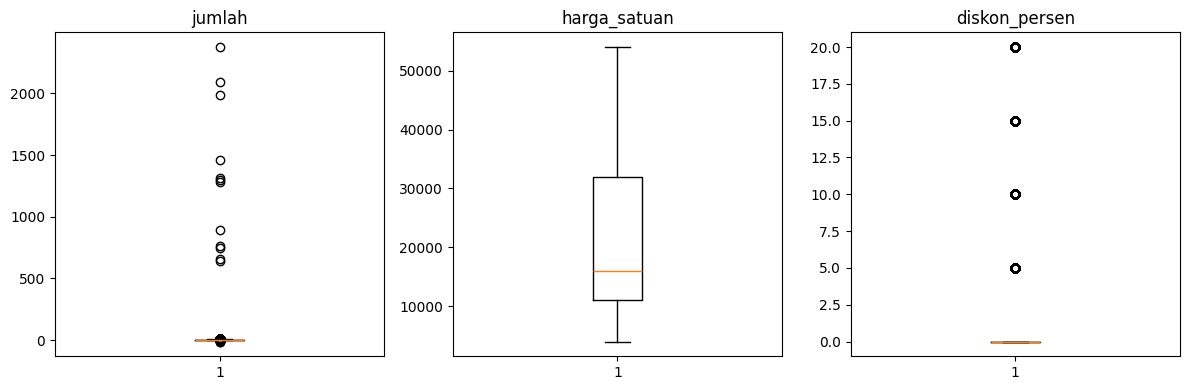

In [45]:
fitur = ["jumlah", "harga_satuan", "diskon_persen"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, kolom in zip(axes, fitur):
    ax.boxplot(df[kolom])
    ax.set_title(kolom)

plt.tight_layout()
plt.show()

In [51]:
for i in fitur:
    print(df[i].value_counts())

jumlah
 1       1956
 2       1211
 3        743
 4        535
 6        353
 12       150
-1         16
-2         12
-3          4
-4          4
-12         2
-6          2
 1456       1
 892        1
 661        1
 2375       1
 1280       1
 2093       1
 759        1
 641        1
 1310       1
 746        1
 1983       1
 1301       1
Name: count, dtype: int64
harga_satuan
11000    205
11500    178
13500    163
12500    155
7000     151
        ... 
30000     28
27500     28
4000      27
27000     26
26000     21
Name: count, Length: 80, dtype: int64
diskon_persen
0     3823
10     418
5      345
15     270
20     144
Name: count, dtype: int64


## 6. Pilih transaksi yang dihitung

- **Status** harus `SELESAI`. Transaksi `BATAL` (dibatalkan) dan `RETUR` (dikembalikan) tidak dihitung sebagai pendapatan.
- **Jumlah** harus antara 1 dan 12. Jumlah negatif dan angka sangat besar (ratusan atau ribuan) dianggap salah input.

In [54]:
data = df[
    (df["status"] == "SELESAI") &
    (df["jumlah"] >= 1) &
    (df["jumlah"] <= 12)
].copy()

print("Transaksi yang dihitung:", len(data))
print("Transaksi yang dibuang :", len(df) - len(data))

Transaksi yang dihitung: 4672
Transaksi yang dibuang : 328


## 7. Hitung pendapatan per tahun

Rumus per transaksi:

**pendapatan = jumlah × harga_satuan × (1 − diskon_persen / 100)**

Harga satuan dianggap harga sebelum diskon.

In [57]:
data["pendapatan"] = data["jumlah"] * data["harga_satuan"] * (1 - data["diskon_persen"] / 100)

pendapatan_tahunan = data.groupby("tahun")["pendapatan"].sum().round(0).astype(int)

for tahun, nilai in pendapatan_tahunan.items():
    print(f"Pendapatan {tahun}: Rp {nilai:,.0f}".replace(",", "."))

Pendapatan 2024: Rp 127.406.475
Pendapatan 2025: Rp 135.001.100


## 8. Grafik

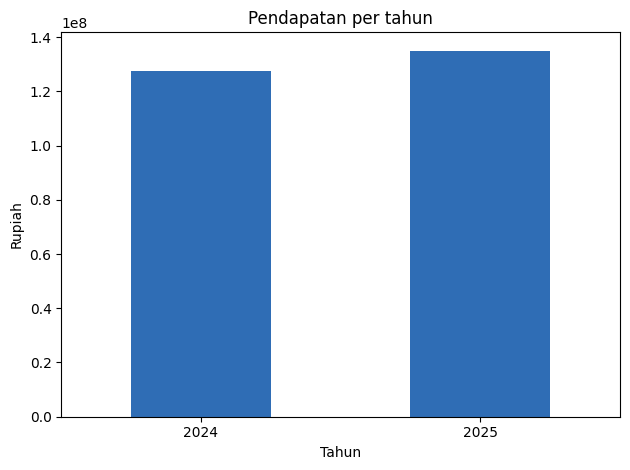

In [60]:
os.makedirs("hasil", exist_ok=True)

pendapatan_tahunan.plot(kind="bar", color="#2F6DB5", title="Pendapatan per tahun")
plt.ylabel("Rupiah")
plt.xlabel("Tahun")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("hasil/pendapatan_per_tahun.png", dpi=150)
plt.show()

## 9. Simpan hasil

In [10]:
pendapatan_tahunan.reset_index().to_csv("hasil/pendapatan_per_tahun.csv", index=False)
print(pd.read_csv("hasil/pendapatan_per_tahun.csv"))

   tahun  pendapatan
0   2024   127406475
1   2025   135001100
